In [20]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset

df = pd.read_csv('/content/sales_data_analysis_sample.csv')

# Display project message

print("SALES DATA ANALYSIS PROJECT")
print("--------------------------------")

# Display first five records

print("\nFirst Five Records:")
display(df.head())

# Display dataset dimensions

print("\nDataset Shape:", df.shape)

SALES DATA ANALYSIS PROJECT
--------------------------------

First Five Records:


,OrderID,OrderDate,Region,State,City,Category,SubCategory,Product,Quantity,UnitPrice,Discount,Sales,Profit,PaymentMode
0,ORD0391,2025-01-02,South,Tamil Nadu,Coimbatore,Clothing,Footwear,Sneakers,1,2400,0.05,2280.0,620.78,Cash
1,ORD0405,2025-01-03,South,Tamil Nadu,Chennai,Electronics,Phones,Headphones,5,1500,0.00,7500.0,1409.26,Net Banking
2,ORD0366,2025-01-03,East,Odisha,Bhubaneswar,Home & Kitchen,Storage,Storage Box,4,500,0.00,2000.0,762.36,Cash
3,ORD0394,2025-01-03,West,Gujarat,Vadodara,Office Supplies,Paper Products,Printer Paper,5,450,0.05,2137.5,429.32,Credit Card
4,ORD0422,2025-01-03,South,Karnataka,Bengaluru,Office Supplies,Furniture,Desk,2,9000,0.10,16200.0,2537.47,Cash



Dataset Shape: (500, 14)


In [21]:
# DATA EXPLORATION

# 1. Dataset dimensions
print("1. Dataset Shape:", df.shape)

# 2. Column names
print("\n2. Column Names:")
print(df.columns.tolist())

# 3. Dataset information
print("\n3. Dataset Information:")
df.info()

# 4. Missing values
print("\n4. Missing Values:")
print(df.isnull().sum())

# 5. Duplicate records
print("\n5. Duplicate Rows:")
print(df.duplicated().sum())

# 6. Statistical summary
print("\n6. Statistical Summary:")
display(df.describe())

1. Dataset Shape: (500, 14)

2. Column Names:
['OrderID', 'OrderDate', 'Region', 'State', 'City', 'Category', 'SubCategory', 'Product', 'Quantity', 'UnitPrice', 'Discount', 'Sales', 'Profit', 'PaymentMode']

3. Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   OrderID      500 non-null    object 
 1   OrderDate    500 non-null    object 
 2   Region       500 non-null    object 
 3   State        500 non-null    object 
 4   City         500 non-null    object 
 5   Category     500 non-null    object 
 6   SubCategory  500 non-null    object 
 7   Product      500 non-null    object 
 8   Quantity     500 non-null    int64  
 9   UnitPrice    500 non-null    int64  
 10  Discount     500 non-null    float64
 11  Sales        500 non-null    float64
 12  Profit       500 non-null    float64
 13  PaymentMode  500 non-null   

,Quantity,UnitPrice,Discount,Sales,Profit
count,500.000000,500.000000,500.000000,500.00000,500.000000
mean,3.004000,3386.040000,0.105700,9242.24400,2538.790220
std,1.458849,9386.544303,0.068935,29244.67743,9228.632138
min,1.000000,120.000000,0.000000,96.00000,21.670000
25%,2.000000,450.000000,0.050000,926.25000,231.957500
50%,3.000000,900.000000,0.100000,2245.00000,605.540000
75%,4.000000,2200.000000,0.150000,5400.00000,1422.902500
max,5.000000,55000.000000,0.200000,275000.00000,114420.400000


In [22]:
# DATA CLEANING

# 1. Check missing values
print("Missing Values:", df.isnull().sum().sum())

# 2. Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())

# 3. Convert OrderDate into datetime format
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

# 4. Check data types after conversion
print("\nUpdated Data Types:")
print(df.dtypes)

# 5. Check invalid numerical values
print("\nNegative Quantities:", (df['Quantity'] < 0).sum())
print("Negative Prices:", (df['UnitPrice'] < 0).sum())
print("Invalid Discounts:",
      ((df['Discount'] < 0) | (df['Discount'] > 1)).sum())

# 6. Display cleaned dataset
print("\nCleaned Dataset:")
display(df.head())

print("\nFinal Dataset Shape:", df.shape)

Missing Values: 0
Duplicate Rows: 0

Updated Data Types:
OrderID                object
OrderDate      datetime64[ns]
Region                 object
State                  object
City                   object
Category               object
SubCategory            object
Product                object
Quantity                int64
UnitPrice               int64
Discount              float64
Sales                 float64
Profit                float64
PaymentMode            object
dtype: object

Negative Quantities: 0
Negative Prices: 0
Invalid Discounts: 0

Cleaned Dataset:


,OrderID,OrderDate,Region,State,City,Category,SubCategory,Product,Quantity,UnitPrice,Discount,Sales,Profit,PaymentMode
0,ORD0391,2025-01-02,South,Tamil Nadu,Coimbatore,Clothing,Footwear,Sneakers,1,2400,0.05,2280.0,620.78,Cash
1,ORD0405,2025-01-03,South,Tamil Nadu,Chennai,Electronics,Phones,Headphones,5,1500,0.00,7500.0,1409.26,Net Banking
2,ORD0366,2025-01-03,East,Odisha,Bhubaneswar,Home & Kitchen,Storage,Storage Box,4,500,0.00,2000.0,762.36,Cash
3,ORD0394,2025-01-03,West,Gujarat,Vadodara,Office Supplies,Paper Products,Printer Paper,5,450,0.05,2137.5,429.32,Credit Card
4,ORD0422,2025-01-03,South,Karnataka,Bengaluru,Office Supplies,Furniture,Desk,2,9000,0.10,16200.0,2537.47,Cash



Final Dataset Shape: (500, 14)


In [23]:
# EXPLORATORY DATA ANALYSIS (EDA)

# 1. Calculate total sales
total_sales = df['Sales'].sum()

# 2. Calculate total profit
total_profit = df['Profit'].sum()

# 3. Calculate total orders
total_orders = df['OrderID'].nunique()

# 4. Calculate total quantity sold
total_quantity = df['Quantity'].sum()

# 5. Calculate average order value
average_order_value = total_sales / total_orders

# 6. Calculate profit margin
profit_margin = (total_profit / total_sales) * 100

# Display results
print("SALES PERFORMANCE ANALYSIS")
print("----------------------------------")

print(f"Total Sales: Rs. {total_sales:,.2f}")
print(f"Total Profit: Rs. {total_profit:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Total Quantity Sold: {total_quantity}")
print(f"Average Order Value: Rs. {average_order_value:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")

SALES PERFORMANCE ANALYSIS
----------------------------------
Total Sales: Rs. 4,621,122.00
Total Profit: Rs. 1,269,395.11
Total Orders: 500
Total Quantity Sold: 1502
Average Order Value: Rs. 9,242.24
Profit Margin: 27.47%


In [24]:
# PRODUCT AND CATEGORY ANALYSIS

# 1. Sales by category
category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

print("1. Total Sales by Category:")
display(category_sales)

# 2. Profit by category
category_profit = df.groupby('Category')['Profit'].sum().sort_values(ascending=False)

print("\n2. Total Profit by Category:")
display(category_profit)

# 3. Quantity sold by product
product_quantity = df.groupby('Product')['Quantity'].sum().sort_values(ascending=False)

print("\n3. Top 10 Products by Quantity Sold:")
display(product_quantity.head(10))

# 4. Sales by individual product
product_sales = df.groupby('Product')['Sales'].sum().sort_values(ascending=False)

print("\n4. Top 10 Products by Sales:")
display(product_sales.head(10))

1. Total Sales by Category:


,Sales
Category,
Electronics,2868062.5
Office Supplies,931677.0
Clothing,413445.0
Home & Kitchen,407937.5



2. Total Profit by Category:


,Profit
Category,
Electronics,810790.47
Office Supplies,236261.04
Home & Kitchen,113116.19
Clothing,109227.41



3. Top 10 Products by Quantity Sold:


,Quantity
Product,
Desk,65
Printer Paper,64
Keyboard,58
Folders,57
Webcam,56
Lunch Box,55
Toaster,50
Dress,49
Laptop,47



4. Top 10 Products by Sales:


,Sales
Product,
Laptop,2326500.0
Desk,508500.0
Office Chair,271050.0
Smartphone,248400.0
Webcam,104500.0
Sneakers,87360.0
Bookshelf,86640.0
Mixer Grinder,86100.0
Toaster,80640.0


In [25]:
# REGIONAL SALES ANALYSIS

# 1. Sales by region
region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)

print("1. Sales by Region:")
display(region_sales)

# 2. Profit by region
region_profit = df.groupby('Region')['Profit'].sum().sort_values(ascending=False)

print("\n2. Profit by Region:")
display(region_profit)

# 3. Sales by state
state_sales = df.groupby('State')['Sales'].sum().sort_values(ascending=False)

print("\n3. Top 10 States by Sales:")
display(state_sales.head(10))

# 4. Sales by city
city_sales = df.groupby('City')['Sales'].sum().sort_values(ascending=False)

print("\n4. Top 10 Cities by Sales:")
display(city_sales.head(10))

# 5. Orders by region
region_orders = df.groupby('Region')['OrderID'].nunique().sort_values(ascending=False)

print("\n5. Number of Orders by Region:")
display(region_orders)

1. Sales by Region:


,Sales
Region,
East,1905716.5
North,1096664.0
West,951041.0
South,667700.5



2. Profit by Region:


,Profit
Region,
East,512339.09
North,319991.69
West,279469.95
South,157594.38



3. Top 10 States by Sales:


,Sales
State,
Odisha,694219.0
Maharashtra,662328.0
West Bengal,640272.5
Bihar,571225.0
Delhi,496157.5
Rajasthan,386867.5
Karnataka,316621.0
Gujarat,288713.0
Uttar Pradesh,213639.0



4. Top 10 Cities by Sales:


,Sales
City,
Bhubaneswar,544274.0
New Delhi,496157.5
Gaya,475502.5
Nagpur,469067.0
Siliguri,373305.0
Udaipur,273663.0
Kolkata,266967.5
Mysuru,216032.5
Cuttack,149945.0



5. Number of Orders by Region:


,OrderID
Region,
West,134
East,125
North,123
South,118


In [26]:
# MONTHLY SALES ANALYSIS

# Extract month from OrderDate
df['Month'] = df['OrderDate'].dt.month
df['Month_Name'] = df['OrderDate'].dt.strftime('%B')

# 1. Calculate monthly sales
monthly_sales = df.groupby('Month')['Sales'].sum()

print("1. Monthly Sales:")
display(monthly_sales)

# 2. Calculate monthly profit
monthly_profit = df.groupby('Month')['Profit'].sum()

print("\n2. Monthly Profit:")
display(monthly_profit)

# 3. Find highest sales month
highest_month = monthly_sales.idxmax()

print("\n3. Highest Sales Month:",
      pd.to_datetime(str(highest_month), format='%m').strftime('%B'))

# 4. Find lowest sales month
lowest_month = monthly_sales.idxmin()

print("4. Lowest Sales Month:",
      pd.to_datetime(str(lowest_month), format='%m').strftime('%B'))

1. Monthly Sales:


,Sales
Month,
1,514205.0
2,678658.5
3,198880.5
4,151940.5
5,332695.5
6,806144.0
7,207749.0
8,220497.5
9,546938.0



2. Monthly Profit:


,Profit
Month,
1,159094.35
2,175430.09
3,55077.11
4,34357.12
5,79708.67
6,220766.35
7,46469.76
8,63921.05
9,136690.32



3. Highest Sales Month: June
4. Lowest Sales Month: April


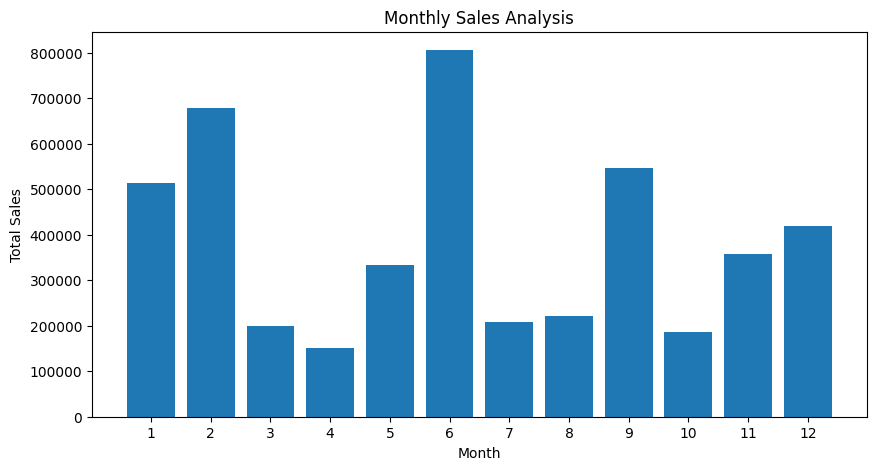

In [27]:
# DATA VISUALIZATION

# Monthly Sales Bar Chart

plt.figure(figsize=(10, 5))

plt.bar(monthly_sales.index, monthly_sales.values)

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(range(1, 13))

plt.show()

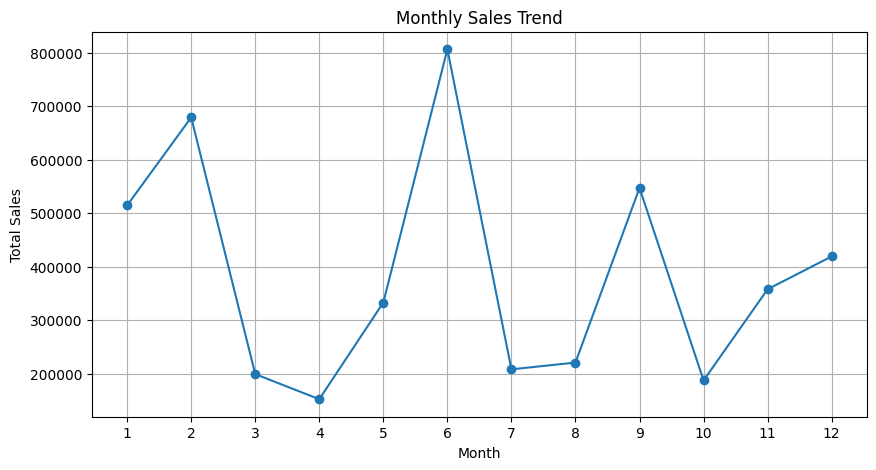

In [28]:
# Monthly SalesTrend Line Chart

plt.figure(figsize=(10, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker='o')

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

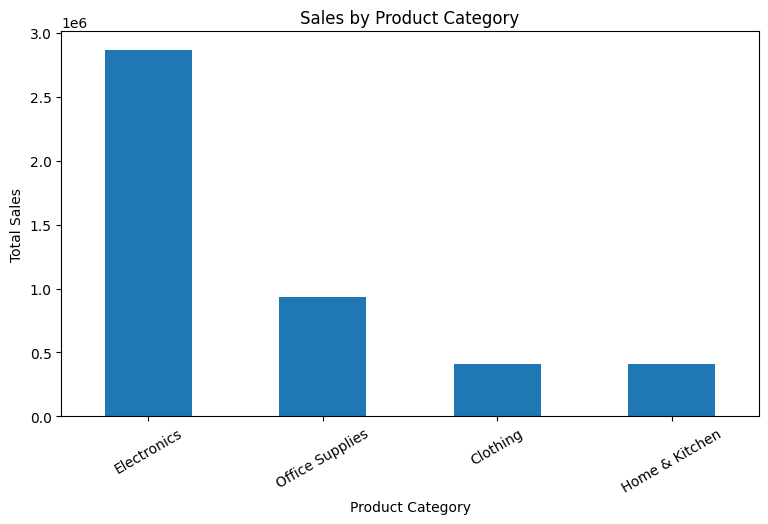

In [29]:
# Sales by Product Category

plt.figure(figsize=(9, 5))

category_sales.plot(kind='bar')

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=30)
plt.show()

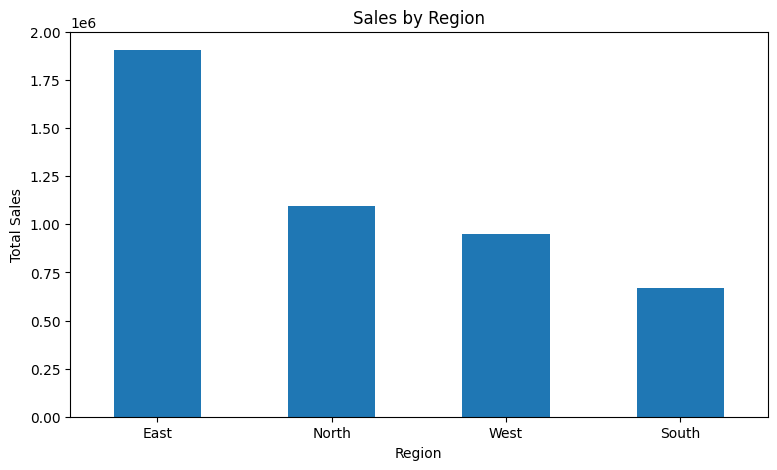

In [30]:
# Sales by Region

plt.figure(figsize=(9, 5))

region_sales.plot(kind='bar')

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.xticks(rotation=0)
plt.show()

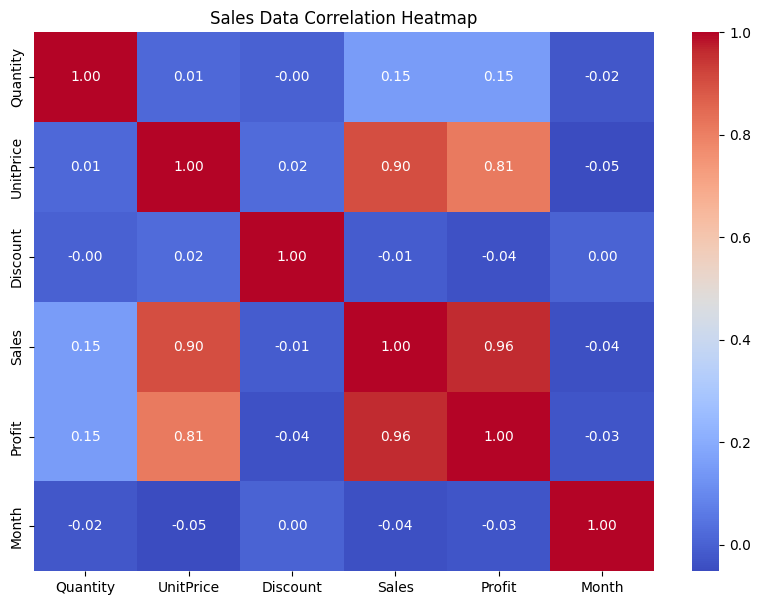

In [32]:
# CORRELATION HEATMAP

numeric_data = df.select_dtypes(include='number')

correlation = numeric_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Sales Data Correlation Heatmap")

plt.show()

In [33]:
# SQL ANALYSIS

import sqlite3

# Create a database
conn = sqlite3.connect('sales_analysis.db')

# Convert Pandas DataFrame into SQL table
df.to_sql('sales', conn, if_exists='replace', index=False)

print("SQL Database Created Successfully!")
print("Sales table created successfully!")

SQL Database Created Successfully!
Sales table created successfully!


In [34]:
# Display first 5 records using SQL

query = """
SELECT *
FROM sales
LIMIT 5;
"""

result = pd.read_sql_query(query, conn)

display(result)

,OrderID,OrderDate,Region,State,City,Category,SubCategory,Product,Quantity,UnitPrice,Discount,Sales,Profit,PaymentMode,Month,Month_Name
0,ORD0391,2025-01-02 00:00:00,South,Tamil Nadu,Coimbatore,Clothing,Footwear,Sneakers,1,2400,0.05,2280.0,620.78,Cash,1,January
1,ORD0405,2025-01-03 00:00:00,South,Tamil Nadu,Chennai,Electronics,Phones,Headphones,5,1500,0.00,7500.0,1409.26,Net Banking,1,January
2,ORD0366,2025-01-03 00:00:00,East,Odisha,Bhubaneswar,Home & Kitchen,Storage,Storage Box,4,500,0.00,2000.0,762.36,Cash,1,January
3,ORD0394,2025-01-03 00:00:00,West,Gujarat,Vadodara,Office Supplies,Paper Products,Printer Paper,5,450,0.05,2137.5,429.32,Credit Card,1,January
4,ORD0422,2025-01-03 00:00:00,South,Karnataka,Bengaluru,Office Supplies,Furniture,Desk,2,9000,0.10,16200.0,2537.47,Cash,1,January


In [36]:
# Total Sales by Product Category

query = """
SELECT
    Category,
    SUM(Sales) AS Total_Sales
FROM sales
GROUP BY Category
ORDER BY Total_Sales DESC;
"""

result = pd.read_sql_query(query, conn)

display(result)

,Category,Total_Sales
0,Electronics,2868062.5
1,Office Supplies,931677.0
2,Clothing,413445.0
3,Home & Kitchen,407937.5


In [37]:
# Total Profit by Region

query = """
SELECT
    Region,
    SUM(Profit) AS Total_Profit
FROM sales
GROUP BY Region
ORDER BY Total_Profit DESC;
"""

result = pd.read_sql_query(query, conn)

display(result)

,Region,Total_Profit
0,East,512339.09
1,North,319991.69
2,West,279469.95
3,South,157594.38


In [38]:
# Top 10 Products by Sales

query = """
SELECT
    Product,
    SUM(Sales) AS Total_Sales
FROM sales
GROUP BY Product
ORDER BY Total_Sales DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

display(result)

,Product,Total_Sales
0,Laptop,2326500.0
1,Desk,508500.0
2,Office Chair,271050.0
3,Smartphone,248400.0
4,Webcam,104500.0
5,Sneakers,87360.0
6,Bookshelf,86640.0
7,Mixer Grinder,86100.0
8,Toaster,80640.0
9,Dress,79470.0


In [39]:
# Monthly Sales Analysis Using SQL

query = """
SELECT
    strftime('%m', OrderDate) AS Month,
    SUM(Sales) AS Total_Sales
FROM sales
GROUP BY Month
ORDER BY Month;
"""

monthly_sql = pd.read_sql_query(query, conn)

display(monthly_sql)

,Month,Total_Sales
0,01,514205.0
1,02,678658.5
2,03,198880.5
3,04,151940.5
4,05,332695.5
5,06,806144.0
6,07,207749.0
7,08,220497.5
8,09,546938.0
9,10,187039.5


In [40]:
# Average Order Value Using SQL

query = """
SELECT
    COUNT(DISTINCT OrderID) AS Total_Orders,
    SUM(Sales) AS Total_Sales,
    AVG(Sales) AS Average_Order_Value
FROM sales;
"""

aov_result = pd.read_sql_query(query, conn)

display(aov_result)

,Total_Orders,Total_Sales,Average_Order_Value
0,500,4621122.0,9242.244
